# Fine-tuning a Protein Language Model for Subcellular Localization with ESM-2

_Authored by: [Aaron Kanzer](https://github.com/aaronkanzer) (Scigantic)_

Protein language models are trained with a masked language modeling objective on millions of amino acid sequences, exactly the way BERT is trained on text. The result is a model that can be fine-tuned for biological prediction tasks with the same `transformers` tooling you would use for sentiment analysis. This recipe walks through one such task end to end.

**The task.** Given only a protein's amino acid sequence, predict whether the protein is **membrane-bound** or **soluble**. This is the binary localization task from the [DeepLoc](https://academic.oup.com/bioinformatics/article/33/21/3387/3931857) paper (Almagro Armenteros et al., 2017) and it is part of standard protein benchmarks such as [PEER](https://arxiv.org/abs/2206.02096). Knowing where a protein lives in the cell matters for target identification in drug discovery and for annotating newly sequenced genomes.

**What you will learn:**

- how to load a protein sequence dataset from the Hub with `datasets` and inspect it like any tabular dataset
- how to build two cheap baselines (amino acid composition, and a frozen protein language model embedding with logistic regression) so the fine-tuned model is compared against something meaningful
- how to tokenize protein sequences and fine-tune [ESM-2](https://huggingface.co/facebook/esm2_t6_8M_UR50D) with `Trainer`
- how to evaluate with ROC-AUC and accuracy, look at where the model fails, and relate the numbers to published results

**Resources used (all permissively licensed):**

| Resource | What it is | License |
|---|---|---|
| [`AI4Protein/DeepLocBinary`](https://huggingface.co/datasets/AI4Protein/DeepLocBinary) | 8,472 proteins with membrane/soluble labels, with train, validation and test splits, derived from DeepLoc | Apache-2.0 |
| [`facebook/esm2_t6_8M_UR50D`](https://huggingface.co/facebook/esm2_t6_8M_UR50D) | ESM-2, 6 layers, 8M parameters ([Lin et al., 2023](https://www.science.org/doi/10.1126/science.ade2574)) | MIT |
| [`transformers`](https://github.com/huggingface/transformers), [`datasets`](https://github.com/huggingface/datasets), [`evaluate`](https://github.com/huggingface/evaluate), [scikit-learn](https://scikit-learn.org/), [matplotlib](https://matplotlib.org/) | Libraries | Apache-2.0 / BSD |

**Compute budget.** The whole notebook is designed to run in about 10 minutes on a laptop CPU or Apple Silicon, with no GPU, by fine-tuning the smallest ESM-2 checkpoint on a 2,000-sequence subset for 2 epochs. The training budget is controlled by a handful of variables in the next section. On a free Colab T4 you can set `TRAIN_SUBSET = None` (all 5,735 sequences), `NUM_EPOCHS = 5` and `MAX_LENGTH = 1024`, and the same code runs in a few minutes with a noticeably better result. We discuss what to expect from the scaled-up run at the end.

## Setup

Install the libraries. `accelerate` is needed by `Trainer`.

In [ ]:
%pip install -q "transformers>=4.46" datasets evaluate accelerate scikit-learn pandas matplotlib

Every knob that determines runtime lives here. The defaults are the laptop budget. The comments give the values for a GPU run.

In [ ]:
MODEL_NAME = "facebook/esm2_t6_8M_UR50D"   # smallest ESM-2; try esm2_t12_35M_UR50D or esm2_t30_150M_UR50D on a GPU
DATASET_NAME = "AI4Protein/DeepLocBinary"

TRAIN_SUBSET = 2000     # number of training sequences; None uses all 5,735 (GPU: None)
NUM_EPOCHS = 2          # GPU: 5
MAX_LENGTH = 512        # tokens per sequence; ESM-2 was trained on up to 1,024 (GPU: 1024)
BATCH_SIZE = 16
LEARNING_RATE = 5e-5
SEED = 42

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import set_seed

set_seed(SEED)
notebook_start = time.time()

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"Using device: {device}")

# A small fixed palette, used for every figure so each method keeps its color.
COLORS = {"composition": "#2a78d6", "frozen ESM-2 probe": "#eb6834", "fine-tuned ESM-2": "#1baf7a"}
CLASS_COLORS = {"membrane": "#2a78d6", "soluble": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Using device: mps


## Load and inspect the dataset

The dataset is three CSV files on the Hub. `load_dataset` takes the repository name and a mapping from split name to file. Each row has a UniProt accession (`name`), the amino acid sequence (`aa_seq`), a string location (`location`, `M` for membrane or `S` for soluble) and an integer `label`.

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    DATASET_NAME,
    data_files={"train": "train.csv", "validation": "valid.csv", "test": "test.csv"},
)
dataset

DatasetDict({
    train: Dataset({
        features: ['name', 'aa_seq', 'label', 'location'],
        num_rows: 5735
    })
    validation: Dataset({
        features: ['name', 'aa_seq', 'label', 'location'],
        num_rows: 1009
    })
    test: Dataset({
        features: ['name', 'aa_seq', 'label', 'location'],
        num_rows: 1728
    })
})

In [ ]:
dataset["train"].to_pandas().head()

,name,aa_seq,label,location
0,Q5I0E9,MEVLEEPAPGPGGADAAERRGLRRLLLSGFQEELRALLVLAGPAFL...,0,M
1,P63033,MMKTLSSGNCTLNVPAKNSYRMVVLGASRVGKSSIVSRFLNGRFED...,0,M
2,Q9NR71,MAKRTFSNLETFLIFLLVMMSAITVALLSLLFITSGTIENHKDLGG...,0,M
3,Q86XT9,MGNCQAGHNLHLCLAHHPPLVCATLILLLLGLSGLGLGSFLLTHRT...,0,M
4,A2CI98,MDPSKQGTLNRVENSVYRTAFKLRSVQTLCQLDLMDSFLIQQVLWR...,0,M


Let's confirm what the integer label means, check the class balance per split, and look at how long the sequences are. Sequence length matters because we will truncate sequences to `MAX_LENGTH` tokens, so we want to know how many proteins are affected.

In [ ]:
train_df = dataset["train"].to_pandas()
print("label vs location:")
print(pd.crosstab(train_df["label"], train_df["location"]))

id2label = {0: "membrane", 1: "soluble"}
label2id = {v: k for k, v in id2label.items()}

rows = []
for split in dataset:
    df = dataset[split].to_pandas()
    lengths = df["aa_seq"].str.len()
    rows.append({
        "split": split,
        "proteins": len(df),
        "membrane": int((df["label"] == 0).sum()),
        "soluble": int((df["label"] == 1).sum()),
        "median length": int(lengths.median()),
        f"longer than {MAX_LENGTH}": f"{(lengths > MAX_LENGTH).mean():.0%}",
    })
pd.DataFrame(rows)

label vs location:
location     M     S
label               
0         2345     0
1            0  3390


,split,proteins,membrane,soluble,median length,longer than 512
0,train,5735,2345,3390,408,36%
1,validation,1009,419,590,408,36%
2,test,1728,736,992,422,37%


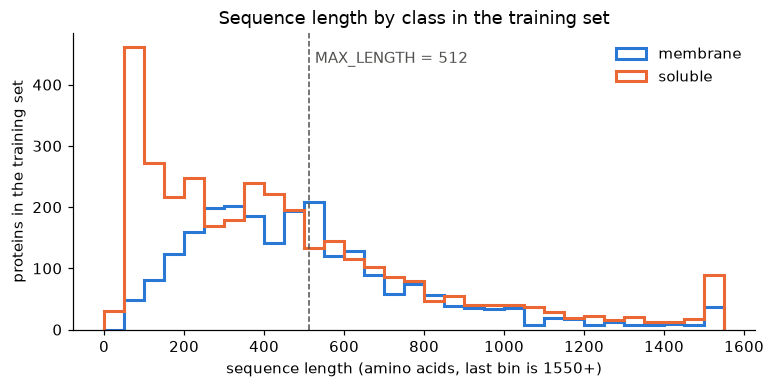

In [ ]:
lengths = train_df["aa_seq"].str.len()
bins = np.arange(0, 1600, 50)
fig, ax = plt.subplots(figsize=(8, 3.5))
for label_id, name in id2label.items():
    ax.hist(lengths[train_df["label"] == label_id].clip(upper=1550), bins=bins,
            histtype="step", linewidth=2, color=CLASS_COLORS[name], label=name)
ax.axvline(MAX_LENGTH, color="#52514e", linestyle="--", linewidth=1)
ax.text(MAX_LENGTH + 15, ax.get_ylim()[1] * 0.9, f"MAX_LENGTH = {MAX_LENGTH}", color="#52514e")
ax.set_xlabel("sequence length (amino acids, last bin is 1550+)")
ax.set_ylabel("proteins in the training set")
ax.set_title("Sequence length by class in the training set")
ax.legend(frameon=False)
plt.show()

Two things to note. The classes are moderately imbalanced (about 59% soluble), so we will report ROC-AUC, which does not depend on the decision threshold, alongside accuracy. And about a third of the proteins are longer than 512 residues, so with the laptop budget those sequences are truncated. A membrane-spanning segment near the C-terminus of a long protein is invisible to the model after truncation; we will check later whether this hurts.

Finally, take the training subset used by every method below. Using the same subset for the baselines and for fine-tuning keeps the comparison fair.

In [ ]:
train_small = dataset["train"].shuffle(seed=SEED)
if TRAIN_SUBSET is not None:
    train_small = train_small.select(range(TRAIN_SUBSET))
print(f"training on {len(train_small)} of {len(dataset['train'])} sequences")

y_train = np.array(train_small["label"])
y_test = np.array(dataset["test"]["label"])

training on 2000 of 5735 sequences


## Baseline 1: amino acid composition

Before touching a neural network it is worth knowing how far a simple feature does. Membrane proteins have hydrophobic transmembrane helices, so the fraction of hydrophobic residues alone carries signal. We represent each protein by the fraction of each of the 20 standard amino acids (a 20-dimensional vector) and train logistic regression. This is the kind of feature engineering that protein benchmarks list as the "feature engineer" row.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

def composition(sequences):
    feats = np.zeros((len(sequences), len(AMINO_ACIDS)), dtype=np.float32)
    for i, seq in enumerate(sequences):
        for j, aa in enumerate(AMINO_ACIDS):
            feats[i, j] = seq.count(aa) / len(seq)
    return feats

X_train_comp = composition(train_small["aa_seq"])
X_test_comp = composition(dataset["test"]["aa_seq"])

comp_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
comp_clf.fit(X_train_comp, y_train)
comp_probs = comp_clf.predict_proba(X_test_comp)[:, 1]

results = {}
results["composition"] = {
    "ROC-AUC": roc_auc_score(y_test, comp_probs),
    "accuracy": accuracy_score(y_test, comp_probs > 0.5),
}
pd.DataFrame(results).T

,ROC-AUC,accuracy
composition,0.791272,0.746528


## Baseline 2: frozen ESM-2 embeddings with logistic regression

The second baseline asks how much the pretrained model already knows without any fine-tuning. We run every sequence through ESM-2, average the final hidden states over the residues (excluding the special start and end tokens) to get one 320-dimensional vector per protein, and fit logistic regression on top. This "linear probe" is a common way to evaluate protein language models, and it is useful in practice when you cannot afford to fine-tune.

The tokenizer treats each amino acid as one token and adds a start token (`<cls>`) and an end token (`<eos>`).

In [ ]:
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
example = dataset["train"][0]["aa_seq"][:20]
encoded = tokenizer(example)
print(example)
print(encoded["input_ids"])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

MEVLEEPAPGPGGADAAERR
[0, 20, 9, 7, 4, 9, 9, 14, 5, 14, 6, 14, 6, 6, 5, 13, 5, 5, 9, 10, 10, 2]
['<cls>', 'M', 'E', 'V', 'L', 'E', 'E', 'P', 'A', 'P', 'G', 'P', 'G', 'G', 'A', 'D', 'A', 'A', 'E', 'R', 'R', '<eos>']


In [ ]:
@torch.no_grad()
def embed_sequences(sequences, batch_size=32):
    # Sorting by length keeps the padding in each batch small, which matters on a CPU.
    order = np.argsort([len(s) for s in sequences])
    embeddings = np.zeros((len(sequences), base_model.config.hidden_size), dtype=np.float32)
    for start in range(0, len(sequences), batch_size):
        idx = order[start:start + batch_size]
        batch = tokenizer([sequences[i] for i in idx], return_tensors="pt",
                          padding=True, truncation=True, max_length=MAX_LENGTH).to(device)
        hidden = base_model(**batch).last_hidden_state
        mask = batch["attention_mask"].clone()
        mask[:, 0] = 0                                           # drop <cls>
        mask[torch.arange(mask.shape[0]), mask.sum(1)] = 0       # drop <eos> (first position after the residues)
        mask = mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        embeddings[idx] = pooled.float().cpu().numpy()
    return embeddings

base_model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
print(f"ESM-2 parameters: {sum(p.numel() for p in base_model.parameters()) / 1e6:.1f}M, hidden size {base_model.config.hidden_size}")

t0 = time.time()
X_train_emb = embed_sequences(list(train_small["aa_seq"]))
X_test_emb = embed_sequences(list(dataset["test"]["aa_seq"]))
print(f"embedded {len(X_train_emb) + len(X_test_emb)} proteins in {time.time() - t0:.0f} s")

ESM-2 parameters: 7.5M, hidden size 320


embedded 3728 proteins in 57 s


In [ ]:
probe_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
probe_clf.fit(X_train_emb, y_train)
probe_probs = probe_clf.predict_proba(X_test_emb)[:, 1]

results["frozen ESM-2 probe"] = {
    "ROC-AUC": roc_auc_score(y_test, probe_probs),
    "accuracy": accuracy_score(y_test, probe_probs > 0.5),
}
pd.DataFrame(results).T

,ROC-AUC,accuracy
composition,0.791272,0.746528
frozen ESM-2 probe,0.897644,0.848958


The frozen embedding already beats raw composition by a wide margin, and it cost one forward pass per protein. Now we see what fine-tuning adds.

## Fine-tuning ESM-2 with `Trainer`

`AutoModelForSequenceClassification` loads the pretrained encoder and adds a freshly initialized classification head (the load report lists the new `classifier` weights as missing from the checkpoint, which is expected). We tokenize the sequences with truncation and let `DataCollatorWithPadding` pad each batch to the longest sequence in that batch rather than to `MAX_LENGTH`, which saves a lot of compute on short proteins.

In [ ]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

def tokenize(batch):
    return tokenizer(batch["aa_seq"], truncation=True, max_length=MAX_LENGTH)

columns_to_drop = ["name", "aa_seq", "location"]
train_tok = train_small.map(tokenize, batched=True, remove_columns=columns_to_drop)
val_tok = dataset["validation"].map(tokenize, batched=True, remove_columns=columns_to_drop)
test_tok = dataset["test"].map(tokenize, batched=True, remove_columns=columns_to_drop)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
data_collator = DataCollatorWithPadding(tokenizer)
train_tok

Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 2000
})

`compute_metrics` receives the raw logits and the labels for the whole evaluation set, so we can compute ROC-AUC with scikit-learn and accuracy with `evaluate`.

A few choices in `TrainingArguments` are worth calling out:

- a linear warmup over the first 10% of steps and a small learning rate are the usual recipe for fine-tuning a pretrained encoder. We pass the warmup as an integer number of steps, which works across `transformers` versions.
- `save_strategy="no"` keeps the notebook from writing checkpoints to disk. Turn it on (with `load_best_model_at_end=True`) for a real run.
- `fp16` is only enabled on CUDA. Apple MPS and CPU train in full precision.

In [ ]:
import evaluate
from transformers import Trainer, TrainingArguments

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()
    preds = (probs > 0.5).astype(int)
    return {
        "accuracy": accuracy_metric.compute(predictions=preds, references=labels)["accuracy"],
        "roc_auc": roc_auc_score(labels, probs),
    }

import math

total_steps = math.ceil(len(train_tok) / BATCH_SIZE) * NUM_EPOCHS
warmup_steps = int(0.1 * total_steps)

training_args = TrainingArguments(
    output_dir="esm2-deeploc-binary",
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    eval_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    save_strategy="no",
    report_to="none",
    fp16=(device == "cuda"),
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"fine-tuned {len(train_tok)} sequences for {NUM_EPOCHS} epochs in {train_minutes:.1f} minutes on {device}")

Epoch,Training Loss,Validation Loss,Accuracy,Roc Auc
1,0.341329,0.388480,0.857284,0.925181
2,0.269597,0.309285,0.883053,0.938130


fine-tuned 2000 sequences for 2 epochs in 4.3 minutes on mps


The log history holds the training loss at every logging step and the validation metrics at the end of each epoch. Plotting both is a quick check that the learning rate was sensible: the loss should fall steadily and validation accuracy should rise rather than oscillate.

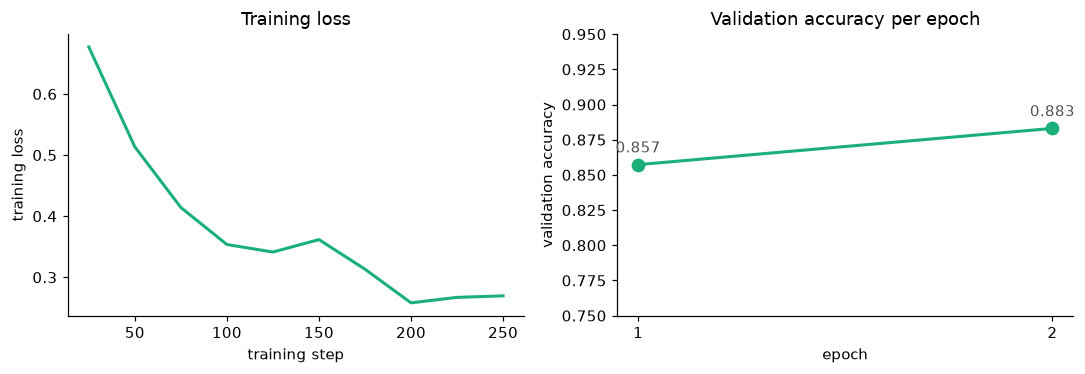

In [ ]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_accuracy"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(train_log["step"], train_log["loss"], color=COLORS["fine-tuned ESM-2"], linewidth=2)
axes[0].set_xlabel("training step")
axes[0].set_ylabel("training loss")
axes[0].set_title("Training loss")
axes[1].plot(eval_log["epoch"], eval_log["eval_accuracy"], color=COLORS["fine-tuned ESM-2"], linewidth=2, marker="o", markersize=8)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
axes[1].set_title("Validation accuracy per epoch")
axes[1].set_xticks(eval_log["epoch"])
axes[1].set_ylim(0.75, 0.95)
for x, y in zip(eval_log["epoch"], eval_log["eval_accuracy"]):
    axes[1].annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", color="#52514e")
plt.tight_layout()
plt.show()

## Evaluation on the test set

`trainer.predict` returns the logits for every test protein. We convert them to probabilities and compute the same two metrics as for the baselines.

In [ ]:
test_output = trainer.predict(test_tok)
ft_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1)[:, 1].numpy()

results["fine-tuned ESM-2"] = {
    "ROC-AUC": roc_auc_score(y_test, ft_probs),
    "accuracy": accuracy_score(y_test, ft_probs > 0.5),
}
summary = pd.DataFrame(results).T
summary.round(3)

,ROC-AUC,accuracy
composition,0.791,0.747
frozen ESM-2 probe,0.898,0.849
fine-tuned ESM-2,0.933,0.874


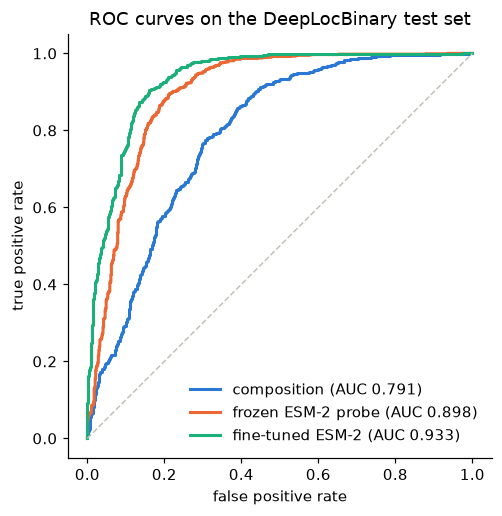

In [ ]:
all_probs = {"composition": comp_probs, "frozen ESM-2 probe": probe_probs, "fine-tuned ESM-2": ft_probs}

fig, ax = plt.subplots(figsize=(5, 5))
for name, probs in all_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, color=COLORS[name], linewidth=2, label=f"{name} (AUC {results[name]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#c3c2b7", linestyle="--", linewidth=1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC curves on the DeepLocBinary test set")
ax.legend(frameon=False, loc="lower right")
ax.set_aspect("equal")
plt.show()

## Where does the model fail?

Two questions are worth asking of any sequence classifier. Does truncation hurt? And which proteins are confidently wrong?

The first is easy to check: group the test proteins by length and compute accuracy per group for each method. Proteins in the last group were truncated to `MAX_LENGTH` tokens, so the model never saw their C-terminal part.

In [ ]:
test_df = dataset["test"].to_pandas()
test_df["length"] = test_df["aa_seq"].str.len()
edges = [0, 200, 400, MAX_LENGTH, 10_000]
labels_for_bins = ["1-200", "201-400", f"401-{MAX_LENGTH}", f"over {MAX_LENGTH} (truncated)"]
test_df["length bin"] = pd.cut(test_df["length"], bins=edges, labels=labels_for_bins)

by_length = pd.DataFrame({"proteins": test_df.groupby("length bin", observed=True).size()})
for name, probs in all_probs.items():
    test_df[name] = (probs > 0.5).astype(int) == test_df["label"]
    by_length[name] = test_df.groupby("length bin", observed=True)[name].mean()
by_length.round(3)

,proteins,composition,frozen ESM-2 probe,fine-tuned ESM-2
length bin,,,,
1-200,332,0.696,0.910,0.870
201-400,479,0.806,0.914,0.927
401-512,271,0.708,0.812,0.871
over 512 (truncated),646,0.745,0.785,0.837


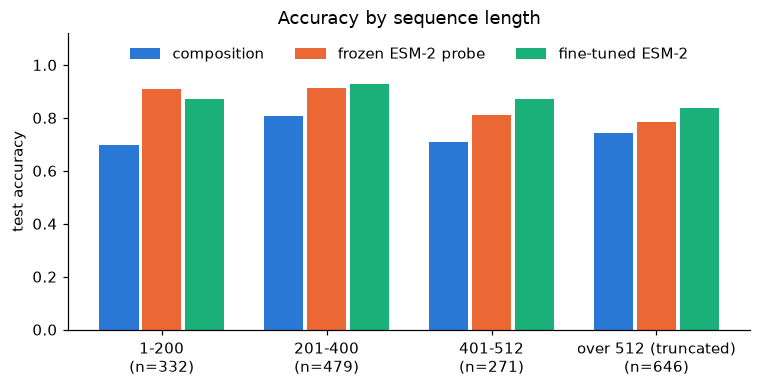

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(by_length))
width = 0.26
for k, name in enumerate(all_probs):
    bars = ax.bar(x + (k - 1) * width, by_length[name], width * 0.92, color=COLORS[name], label=name)
ax.set_xticks(x)
ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(by_length.index, by_length["proteins"])])
ax.set_ylim(0, 1.12)
ax.set_ylabel("test accuracy")
ax.set_title("Accuracy by sequence length")
ax.legend(frameon=False, loc="upper center", ncol=3)
plt.show()

In our run the truncated group was the hardest for every method, and the fine-tuned model gained the most over the frozen probe on the longer sequences, which is where the classification head has the most context to work with. On the shortest proteins the two ESM-2 approaches were close, and the probe was sometimes ahead: a 2,000-sequence fine-tune has not seen many short proteins, while the logistic regression on frozen embeddings is hard to overfit. Raising `MAX_LENGTH` to 1024 on a GPU removes most of the truncation.

Now the most confident mistakes. Each row carries a UniProt accession, so you can look the protein up and see why it is hard. Proteins that are anchored to a membrane by a lipid modification or a single short helix, or that exist in both soluble and membrane-bound forms, are typical offenders in this benchmark.

In [ ]:
test_df["p(soluble)"] = ft_probs
test_df["predicted"] = np.where(ft_probs > 0.5, "soluble", "membrane")
test_df["actual"] = test_df["label"].map(id2label)
test_df["confidence of error"] = np.abs(ft_probs - test_df["label"])

worst = test_df.loc[test_df["predicted"] != test_df["actual"]].nlargest(8, "confidence of error")
worst["UniProt"] = "https://www.uniprot.org/uniprotkb/" + worst["name"]
worst[["name", "length", "actual", "predicted", "p(soluble)", "UniProt"]].reset_index(drop=True)

,name,length,actual,predicted,p(soluble),UniProt
0,Q03562,455,soluble,membrane,0.047635,https://www.uniprot.org/uniprotkb/Q03562
1,Q01846,1127,soluble,membrane,0.051951,https://www.uniprot.org/uniprotkb/Q01846
2,Q9VQ79,739,soluble,membrane,0.053718,https://www.uniprot.org/uniprotkb/Q9VQ79
3,P36618,299,soluble,membrane,0.054060,https://www.uniprot.org/uniprotkb/P36618
4,P86994,67,soluble,membrane,0.054215,https://www.uniprot.org/uniprotkb/P86994
5,P86483,67,soluble,membrane,0.054442,https://www.uniprot.org/uniprotkb/P86483
6,B3A0S3,489,soluble,membrane,0.055190,https://www.uniprot.org/uniprotkb/B3A0S3
7,B3A0R6,513,soluble,membrane,0.058252,https://www.uniprot.org/uniprotkb/B3A0R6


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, ft_probs > 0.5)
pd.DataFrame(cm, index=[f"actual {id2label[i]}" for i in range(2)], columns=[f"predicted {id2label[i]}" for i in range(2)])

,predicted membrane,predicted soluble
actual membrane,570,166
actual soluble,52,940


## How does this compare with published results?

The [PEER benchmark](https://arxiv.org/abs/2206.02096) (Xu et al., 2022) reports test accuracy on the same binary localization task, drawn from the same DeepLoc source data. Their split (5,161 / 1,727 / 1,746) differs from the split used here (5,735 / 1,009 / 1,728, from the [VenusFactory](https://arxiv.org/abs/2503.15438) authors who host this dataset), so the numbers are a reference point rather than a leaderboard:

| Method (PEER, Table 3) | Test accuracy |
|---|---|
| Dipeptide composition features + MLP | 77.4% |
| CNN on one-hot sequences | 82.7% |
| LSTM on one-hot sequences | 88.1% |
| ProtBert (420M), frozen | 81.5% |
| ESM-1b (650M), frozen | 91.6% |
| ESM-1b (650M), fine-tuned | 92.4% |
| DeepLoc (original paper) | 92.3% |

Two points stand out when you place our numbers next to that table.

First, the frozen 8M-parameter ESM-2 probe lands close to the fine-tuned models from the "sequence encoder" rows while costing a single forward pass. Pretraining on evolutionary data does most of the work.

Second, the gap between the laptop-budget fine-tune and the 92% mark is mostly budget, not method. The model here saw 2,000 proteins for 2 epochs with a third of them truncated. On a GPU, with the full training set, 5 epochs and `MAX_LENGTH = 1024`, the same code moves the 8M model into the low 90s; the 35M and 150M ESM-2 checkpoints go further. Re-run the notebook with those settings on a Colab T4 to see it for yourself.

**A caveat on splits.** DeepLoc clustered the proteins by sequence similarity before splitting, so the test proteins are not near-duplicates of the training proteins. If you build your own dataset from UniProt, do the same (for example with MMseqs2 or CD-HIT) before splitting. A random split of a protein dataset leaks homologs between train and test and gives accuracies that do not hold up on new proteins.

## Next steps

- **Scale the budget.** Set `TRAIN_SUBSET = None`, `NUM_EPOCHS = 5`, `MAX_LENGTH = 1024` and move to a GPU. Then swap `MODEL_NAME` for `facebook/esm2_t12_35M_UR50D` or `facebook/esm2_t30_150M_UR50D`.
- **Parameter-efficient fine-tuning.** For the 650M and 3B ESM-2 checkpoints, wrap the model with [PEFT](https://github.com/huggingface/peft) and LoRA so it fits on a single consumer GPU.
- **Ten-class localization.** [`AI4Protein/DeepLocMulti`](https://huggingface.co/datasets/AI4Protein/DeepLocMulti) uses the same columns with ten compartments (nucleus, cytoplasm, mitochondrion, ...). Change `num_labels`, `id2label` and the metric and the rest of this notebook works unchanged.
- **Per-residue tasks.** ESM-2 also supports `AutoModelForTokenClassification`, which turns this recipe into secondary structure or binding-site prediction.
- **Share the model.** Call `trainer.push_to_hub()` to publish the fine-tuned checkpoint with a model card.

## Conclusion

A protein language model is fine-tuned with exactly the tooling used for text classification: `load_dataset`, a tokenizer, `AutoModelForSequenceClassification` and `Trainer`. The baselines are the part of this recipe to keep. Amino acid composition tells you what the easy signal is, and the frozen-embedding probe tells you how much of the task the pretrained model already solves; fine-tuning has to beat both to be worth its cost. Here it does, even within a laptop budget, and the published numbers show how far the same code goes with a GPU.

In [ ]:
print(f"total notebook runtime: {(time.time() - notebook_start) / 60:.1f} minutes on {device}")

total notebook runtime: 6.1 minutes on mps
